In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import glob
from pathlib import Path
import plotly.express as px
import seaborn as sns
import emoji
import re

from collections import Counter
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

## Read csv files

In [3]:
cwd = Path.cwd()
print(cwd)

/Users/emilyjiang/Documents/GitHub/shorts-data


In [4]:
channels_df = pd.read_csv(cwd/'data'/'channels.csv')
channels_df.head()

,channel_id,first_seen_at,channel_title,channel_created_at,total_channel_views,subscriber_count,total_channel_videos
0,UCJgZiklqrfvvfCDO3QhF1Hg,2026-10-12T15:37:58.074627+00:00,kk shorts video,2021-03-26T15:35:22.996177Z,5110271644,3780000,1253
1,UC3NlznSlTlfiNpUhfdJlTiw,2026-10-12T15:37:58.074627+00:00,NLF SoHeL VloG,2024-10-17T06:22:42.920227Z,10787169127,3480000,4666
2,UC5k3V8mUODYybpi2O4O6Atw,2026-10-12T15:37:58.074627+00:00,MegaMarkGames,2013-08-02T01:42:13Z,9939467,432000,3627
3,UC1PlB1jO4-sfrSdqRrvCllA,2026-10-12T15:37:58.074627+00:00,Ram Ji,2026-06-03T05:24:55.322944Z,91083513,95400,269
4,UCTkeM1GjDqx3Bw0q-WVjTNQ,2026-10-12T15:37:58.074627+00:00,小山翔平,2023-02-17T07:46:26.368324Z,84502329,78500,3106


In [5]:
videos_df = pd.read_csv(cwd/'data'/'videos.csv')
videos_df.head()

,video_id,first_seen_at,published_at,channel_id,channel_title,title,description,duration,duration_seconds,tags
0,L5eQJKakz5U,2026-10-12T15:37:58.074627+00:00,2026-10-12T15:15:22Z,UC0cx38VIfmVZva-rYnMmevQ,Amandinha,Abrindo Comprinhas da Shopika 6 #shorts,💜APOIE A AMANDINHA E SE TORNE MEMBRO DO CANAL!...,PT3M,180,[]
1,PdrruRfk_wM,2026-10-12T15:37:58.074627+00:00,2026-10-12T15:10:15Z,UCTHuHxhCBITUuP_AchYSstA,RAXON,Who Cleans Spider-Man’s Webs? 🤣😂 | #shorts,Who Cleans Spider-Man’s Webs? 🤣😂 | #shorts\n\n...,PT48S,48,[]
2,LAhmgGBiESw,2026-10-12T15:37:58.074627+00:00,2026-10-12T15:08:05Z,UC8_NGoazMiGbRPUTQ52_NdQ,Jagiya the fun,Jagiya ke kurkure aur chota bhai🥲🔥| Indian fam...,Jagiya ke kurkure aur chota bhai🥲🔥| Indian fam...,PT32S,32,[]
3,8qJ5k-vbO3E,2026-10-12T15:37:58.074627+00:00,2026-10-12T15:05:44Z,UConRqB3CsY3dAHvVDVsRC4g,Mr_Vlogger,hair loss problem #shorts #minivlog #vlogs,NaN,PT24S,24,[]
4,VP3sxzlp4P0,2026-10-12T15:37:58.074627+00:00,2026-10-12T15:00:07Z,UCa9nE9GRjSOXFL1alnROYEA,Rinconcito Animado,¿Dónde se perdió Bob Esponja? 😱 #viral #shorts,🍍😂 ¡Bob Esponja se perdió intentando encontrar...,PT1M2S,62,[]


In [6]:
countries_df = pd.read_csv(cwd/'data'/'channel_countries.csv')
countries_df.head()

,channel_id,channel_country,country_checked_at
0,UC-MBfVUWu59urBn7WdXGJAA,US,2026-10-16T16:53:21.765904+00:00
1,UC-NIoAJGtb-Ze0KSqR77wuw,BR,2026-10-16T16:53:21.765904+00:00
2,UC-Pjg6st-ragcrS-h51mo0w,NaN,2026-10-16T16:53:21.765904+00:00
3,UC-NHROR0npP1l_6WVse2pxA,IN,2026-10-16T16:53:21.765904+00:00
4,UC-1vgrqMJMNw9E0aIZlU4zQ,IN,2026-10-16T16:53:21.765904+00:00


### Process observation data

In [7]:
observation_files = glob.glob(str(cwd/'data'/'observations'/'*.csv'))

In [8]:
# concat observations into one data frame
observation_df = pd.concat(
    [pd.read_csv(file) for file in observation_files],
    ignore_index=True
)

# sort by video id and observation data
observation_df = observation_df.sort_values(["video_id", "observed_at"])

In [9]:
observation_df.head()

,video_id,observed_at,age_hours,view_count,like_count,comment_count
544859,--S4wKspUZU,2026-10-16T05:53:39.748227+00:00,1.022,3647.0,41.0,9.0
677575,--S4wKspUZU,2026-10-16T06:53:34.896162+00:00,2.021,4641.0,62.0,14.0
785229,--S4wKspUZU,2026-10-16T07:53:31.797928+00:00,3.020,6181.0,76.0,15.0
39423,--S4wKspUZU,2026-10-16T08:53:34.646128+00:00,4.021,7788.0,89.0,18.0
569476,--S4wKspUZU,2026-10-16T09:53:40.665003+00:00,5.023,9396.0,103.0,20.0


In [10]:
observation_df

,video_id,observed_at,age_hours,view_count,like_count,comment_count
544859,--S4wKspUZU,2026-10-16T05:53:39.748227+00:00,1.022,3647.0,41.0,9.0
677575,--S4wKspUZU,2026-10-16T06:53:34.896162+00:00,2.021,4641.0,62.0,14.0
785229,--S4wKspUZU,2026-10-16T07:53:31.797928+00:00,3.020,6181.0,76.0,15.0
39423,--S4wKspUZU,2026-10-16T08:53:34.646128+00:00,4.021,7788.0,89.0,18.0
569476,--S4wKspUZU,2026-10-16T09:53:40.665003+00:00,5.023,9396.0,103.0,20.0
...,...,...,...,...,...,...
150040,zzby5PLoQTI,2026-10-15T16:53:25.697784+00:00,75.885,1090830.0,29120.0,135.0
593915,zzby5PLoQTI,2026-10-15T17:53:27.611454+00:00,76.885,1107786.0,29509.0,136.0
87,zzby5PLoQTI,2026-10-15T18:53:22.502848+00:00,77.884,1165355.0,29805.0,137.0
437863,zzby5PLoQTI,2026-10-15T19:53:23.931139+00:00,78.884,1182118.0,30065.0,138.0


In [11]:
observation_df.groupby("observed_at")["video_id"].nunique()

observed_at
2026-10-12T15:37:59.683152+00:00    50
2026-10-12T15:37:59.850397+00:00    46
2026-10-12T18:14:30.357946+00:00    50
2026-10-12T18:14:30.522698+00:00    50
2026-10-12T18:14:30.671792+00:00    50
                                    ..
2026-10-20T18:53:36.628112+00:00    50
2026-10-20T18:53:36.753789+00:00    50
2026-10-20T18:53:36.907687+00:00    50
2026-10-20T18:53:37.059696+00:00    50
2026-10-20T18:53:37.144834+00:00    24
Name: video_id, Length: 16999, dtype: int64

In [12]:
# add column observation number
observation_df["n_observation"] = observation_df.groupby("video_id").cumcount() + 1

## Data Analysis

### Create new data frame for analysis
Filters videos to only U.S. channels and includes like and view counts at different times

In [13]:
# 1. Get channel IDs for US channels
us_channel_ids = countries_df.loc[
    countries_df["channel_country"] == "US", "channel_id"
].unique()

# 2. Filter channels and videos to US channels
us_channels_df = channels_df[
    channels_df["channel_id"].isin(us_channel_ids)
].copy()

us_videos_df = videos_df[
    videos_df["channel_id"].isin(us_channel_ids)
].copy()

# 3. Get observations at 1, 6, and 24 hours
target_hours = [1, 6, 24]

selected_df = observation_df[
    observation_df["n_observation"].isin(target_hours)
].copy()

# Pivot view counts
views_df = selected_df.pivot_table(
    index="video_id",
    columns="n_observation",
    values="view_count",
    aggfunc="last"
)

views_df.columns = [
    f"views_{int(hour)}hr" for hour in views_df.columns
]

# Pivot like counts
likes_df = selected_df.pivot_table(
    index="video_id",
    columns="n_observation",
    values="like_count",
    aggfunc="last"
)

likes_df.columns = [
    f"likes_{int(hour)}hr" for hour in likes_df.columns
]

# Combine view and like counts
metrics_df = pd.concat(
    [views_df, likes_df], axis=1
).reset_index()

# 4. Select video metadata
video_info = us_videos_df[
    ["video_id", "title", "channel_id", "channel_title"]
].drop_duplicates(subset="video_id")

# 5. Select channel subscriber counts
channel_info = us_channels_df[
    ["channel_id", "subscriber_count"]
].drop_duplicates(subset="channel_id")

# 6. Merge the data
analysis_df = (
    video_info
    .merge(channel_info, on="channel_id", how="left")
    .merge(metrics_df, on="video_id", how="left")
)

# 7. Keep requested columns
analysis_df = analysis_df[
    [
        "title",
        "channel_title",
        "subscriber_count",
        "views_1hr",
        "likes_1hr",
        "views_6hr",
        "likes_6hr",
        "views_24hr",
        "likes_24hr"
    ]
]

analysis_df.head()


,title,channel_title,subscriber_count,views_1hr,likes_1hr,views_6hr,likes_6hr,views_24hr,likes_24hr
0,¡Reyyan abofeteó a Yaren!😲| Hercai #shorts,Hercai Español,753000,227.0,9.0,5700.0,364.0,17513.0,763.0
1,#Spider-Man #Gwen #Shorts #Spider-Gwen,正义格温,141000,57327.0,1175.0,324538.0,4667.0,534648.0,7368.0
2,"DeMario ""Pop had 2 tuds"" Douglas 👌 #patriots #...",New England Patriots,420000,4480.0,350.0,15366.0,655.0,21755.0,806.0
3,"Ian Rapoport: ""All Signs Point"" Toward Caleb W...",Bears Now by Chat Sports,174000,4786.0,511.0,42406.0,1450.0,53081.0,1676.0
4,Name: Grey’s Anatomy | She Chose Freedom.🎬🎬 #m...,FurtherEdit,740000,11167.0,932.0,33607.0,1816.0,73092.0,3232.0


In [14]:
analysis_df.head()

,title,channel_title,subscriber_count,views_1hr,likes_1hr,views_6hr,likes_6hr,views_24hr,likes_24hr
0,¡Reyyan abofeteó a Yaren!😲| Hercai #shorts,Hercai Español,753000,227.0,9.0,5700.0,364.0,17513.0,763.0
1,#Spider-Man #Gwen #Shorts #Spider-Gwen,正义格温,141000,57327.0,1175.0,324538.0,4667.0,534648.0,7368.0
2,"DeMario ""Pop had 2 tuds"" Douglas 👌 #patriots #...",New England Patriots,420000,4480.0,350.0,15366.0,655.0,21755.0,806.0
3,"Ian Rapoport: ""All Signs Point"" Toward Caleb W...",Bears Now by Chat Sports,174000,4786.0,511.0,42406.0,1450.0,53081.0,1676.0
4,Name: Grey’s Anatomy | She Chose Freedom.🎬🎬 #m...,FurtherEdit,740000,11167.0,932.0,33607.0,1816.0,73092.0,3232.0


### Add different virality metrics to analysis data frame

In [15]:
# Absolute growth
analysis_df["views_gained_24hr"] = (
    analysis_df["views_24hr"] - analysis_df["views_1hr"]
)

# Average views gained per hour from hour 1 to hour 24
analysis_df["avg_views_per_hour"] = (
    analysis_df["views_gained_24hr"] / 23
)

# Views relative to channel subscriber count
analysis_df["views_per_subscriber"] = (
    analysis_df["views_24hr"]
    / analysis_df["subscriber_count"].replace(0, np.nan)
)

# Relative growth from hour 1 to hour 24
analysis_df["relative_growth"] = (
    analysis_df["views_gained_24hr"]
    / analysis_df["views_1hr"].replace(0, np.nan)
)

# Like rate at 24 hours
analysis_df["like_rate_24hr"] = (
    analysis_df["likes_24hr"]
    / analysis_df["views_24hr"].replace(0, np.nan)
)

# Growth during the 1-to-6-hour and 6-to-24-hour periods
analysis_df["views_gained_1_to_6hr"] = (
    analysis_df["views_6hr"] - analysis_df["views_1hr"]
)

analysis_df["views_gained_6_to_24hr"] = (
    analysis_df["views_24hr"] - analysis_df["views_6hr"]
)

# Average hourly growth during each period
analysis_df["rate_1_to_6hr"] = (
    analysis_df["views_gained_1_to_6hr"] / 5
)

analysis_df["rate_6_to_24hr"] = (
    analysis_df["views_gained_6_to_24hr"] / 18
)

# Change in average hourly growth rate
analysis_df["growth_acceleration"] = (
    analysis_df["rate_6_to_24hr"]
    - analysis_df["rate_1_to_6hr"]
)

### Use outliers from avg views per hour to identify viral videos

In [16]:
# identify outliers based on avg views per hour

# Calculate average views per hour
analysis_df["avg_views_per_hour"] = (
    analysis_df["views_24hr"] - analysis_df["views_1hr"]
) / 23

valid_df = analysis_df.dropna(
    subset=["avg_views_per_hour"]
).copy()

# IQR outlier threshold
Q1 = valid_df["avg_views_per_hour"].quantile(0.25)
Q3 = valid_df["avg_views_per_hour"].quantile(0.75)
IQR = Q3 - Q1

upper_bound = Q3 + 1.5 * IQR

valid_df["viral"] = (
    valid_df["avg_views_per_hour"] > upper_bound
)

viral_df = valid_df[valid_df["viral"]].copy()
non_viral_df = valid_df[~valid_df["viral"]].copy()

print(f"Outlier threshold: {upper_bound:,.2f} views/hour")
print(f"Viral videos: {len(viral_df)}")
print(f"Non-viral videos: {len(non_viral_df)}")


Outlier threshold: 17,254.87 views/hour
Viral videos: 157
Non-viral videos: 1079


### Correlation matrices comparing viral and non-viral videos

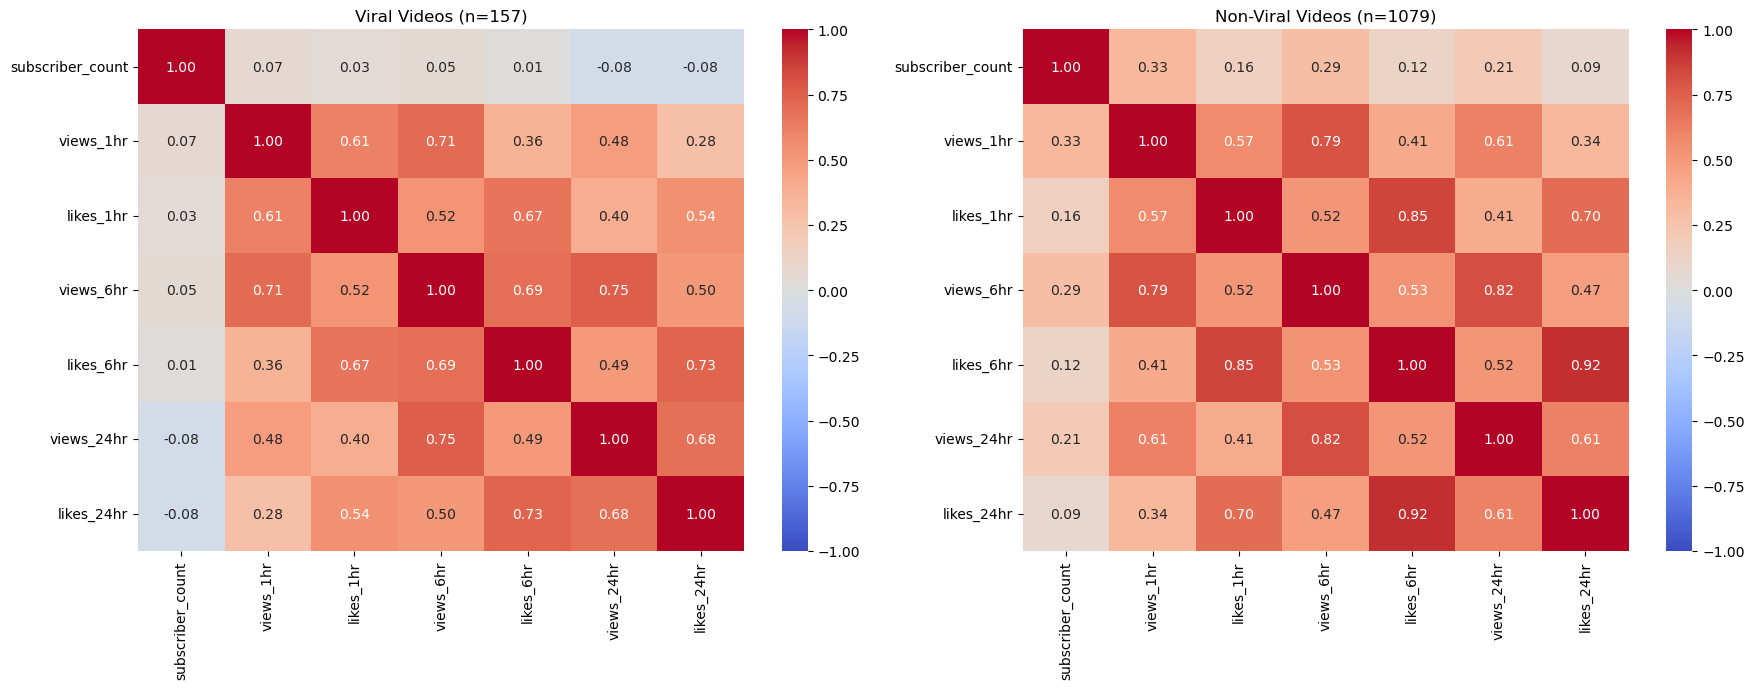

In [ ]:
# create correlation matrices
features = [
    "subscriber_count",
    "views_1hr",
    "likes_1hr",
    "views_6hr",
    "likes_6hr",
    "views_24hr",
    "likes_24hr",
]

# Keep only columns present in the dataframe
features = [
    col for col in features
    if col in valid_df.columns
]

viral_corr = viral_df[features].corr(method="pearson")
non_viral_corr = non_viral_df[features].corr(method="pearson")

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

sns.heatmap(
    viral_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    ax=axes[0]
)
axes[0].set_title(f"Viral Videos (n={len(viral_df)})")

sns.heatmap(
    non_viral_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    ax=axes[1]
)
axes[1].set_title(f"Non-Viral Videos (n={len(non_viral_df)})")

plt.tight_layout()
plt.show()


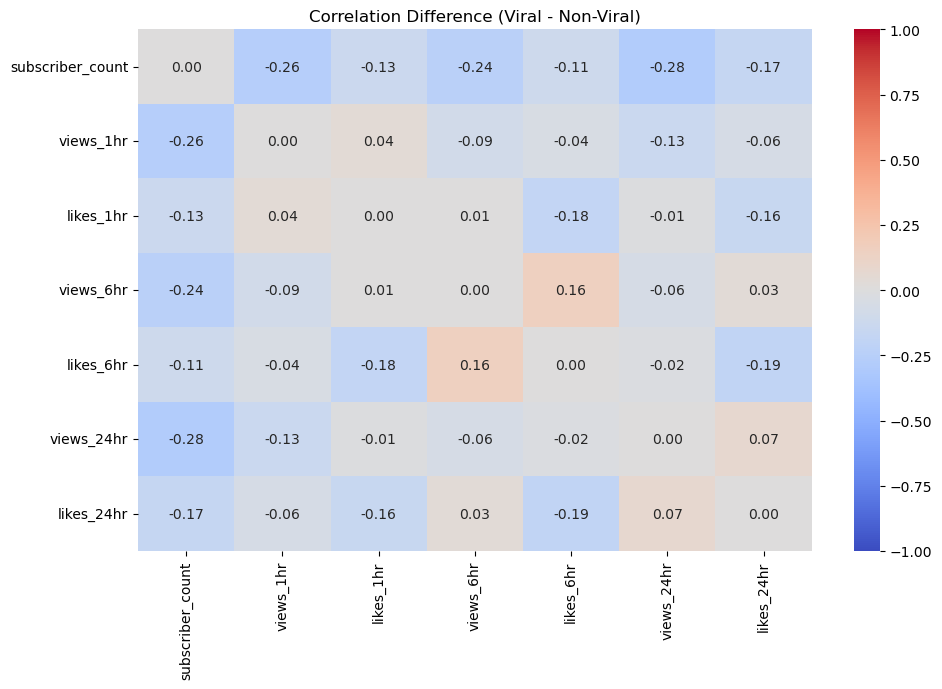

In [18]:
# compare correlation matrices

corr_difference = viral_corr - non_viral_corr

plt.figure(figsize=(10, 7))
sns.heatmap(
    corr_difference,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Correlation Difference (Viral - Non-Viral)")
plt.tight_layout()
plt.show()


### Add title feaures to analysis dataframe

In [19]:
# add title features to the dataset

# Handle missing titles
titles = analysis_df["title"].fillna("").astype(str)

# Length and structure
analysis_df["title_length"] = titles.str.len()
analysis_df["word_count"] = titles.str.split().str.len()

# Capitalization
analysis_df["uppercase_count"] = titles.apply(
    lambda x: sum(c.isupper() for c in x)
)

analysis_df["uppercase_ratio"] = titles.apply(
    lambda x: (
        sum(c.isupper() for c in x if c.isalpha())
        / sum(c.isalpha() for c in x)
        if any(c.isalpha() for c in x)
        else 0
    )
)

analysis_df["is_all_caps"] = titles.apply(
    lambda x: (
        any(c.isalpha() for c in x)
        and all(not c.isalpha() or c.isupper() for c in x)
    )
)

# Punctuation
analysis_df["exclamation_count"] = titles.str.count("!")
analysis_df["question_count"] = titles.str.count(r"\?")
analysis_df["has_exclamation"] = titles.str.contains("!", regex=False)
analysis_df["has_question"] = titles.str.contains("?", regex=False)

analysis_df["has_ellipsis"] = titles.str.contains(
    r"\.\.\.|…", regex=True
)

analysis_df["repeated_punctuation"] = titles.str.contains(
    r"[!?]{2,}", regex=True
)

# Emojis
analysis_df["emoji_count"] = titles.apply(emoji.emoji_count)
analysis_df["has_emoji"] = analysis_df["emoji_count"] > 0

# Hashtags
analysis_df["has_hashtag"] = titles.str.contains("#", regex=False)
analysis_df["hashtag_count"] = titles.apply(
    lambda x: len(re.findall(r"(?<!\w)#\w+", x))
)

# Numbers
analysis_df["has_number"] = titles.str.contains(r"\d", regex=True)
analysis_df["number_count"] = titles.str.count(r"\d")

# Character encoding
analysis_df["is_ascii"] = titles.str.isascii()

analysis_df.head()

,title,channel_title,subscriber_count,views_1hr,likes_1hr,views_6hr,likes_6hr,views_24hr,likes_24hr,views_gained_24hr,...,has_question,has_ellipsis,repeated_punctuation,emoji_count,has_emoji,has_hashtag,hashtag_count,has_number,number_count,is_ascii
0,¡Reyyan abofeteó a Yaren!😲| Hercai #shorts,Hercai Español,753000,227.0,9.0,5700.0,364.0,17513.0,763.0,17286.0,...,False,False,False,1,True,True,1,False,0,False
1,#Spider-Man #Gwen #Shorts #Spider-Gwen,正义格温,141000,57327.0,1175.0,324538.0,4667.0,534648.0,7368.0,477321.0,...,False,False,False,0,False,True,4,False,0,True
2,"DeMario ""Pop had 2 tuds"" Douglas 👌 #patriots #...",New England Patriots,420000,4480.0,350.0,15366.0,655.0,21755.0,806.0,17275.0,...,False,False,False,1,True,True,3,True,1,False
3,"Ian Rapoport: ""All Signs Point"" Toward Caleb W...",Bears Now by Chat Sports,174000,4786.0,511.0,42406.0,1450.0,53081.0,1676.0,48295.0,...,False,False,False,0,False,True,3,False,0,True
4,Name: Grey’s Anatomy | She Chose Freedom.🎬🎬 #m...,FurtherEdit,740000,11167.0,932.0,33607.0,1816.0,73092.0,3232.0,61925.0,...,False,False,False,2,True,True,3,False,0,False


### Identify frequently used words in titles

In [20]:
# Get titles and convert to lowercase
titles = analysis_df["title"].dropna().str.lower()

# Extract words, excluding common English stop words
stop_words = set(ENGLISH_STOP_WORDS)

all_words = []

for title in titles:
    words = re.findall(r"\b[a-z]+\b", title)
    all_words.extend(
        word for word in words
        if word not in stop_words and len(word) > 1
    )

# Count occurrences
word_counts = Counter(all_words)

# Display the 30 most common words
word_counts.most_common(30)

[('shorts', 1398),
 ('funny', 123),
 ('roblox', 117),
 ('viral', 91),
 ('minecraft', 58),
 ('comedy', 57),
 ('nfl', 50),
 ('cosplay', 47),
 ('fyp', 46),
 ('shortvideo', 44),
 ('memes', 44),
 ('vs', 43),
 ('foryou', 40),
 ('trending', 37),
 ('kpop', 33),
 ('new', 31),
 ('movie', 29),
 ('spiderman', 29),
 ('challenge', 27),
 ('ranking', 26),
 ('usa', 25),
 ('gaming', 24),
 ('best', 24),
 ('spider', 23),
 ('man', 23),
 ('animation', 22),
 ('viralvideo', 22),
 ('family', 21),
 ('football', 21),
 ('ytshorts', 20)]

Common words overall

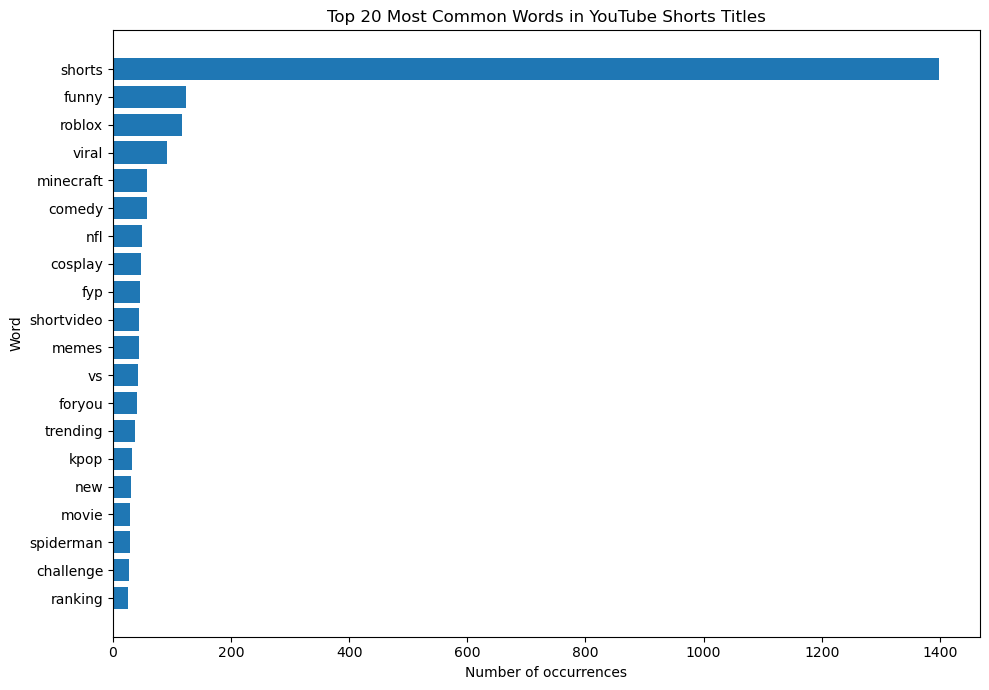

In [21]:
top_words = word_counts.most_common(20)

words, counts = zip(*top_words)

plt.figure(figsize=(10, 7))
plt.barh(words[::-1], counts[::-1])
plt.xlabel("Number of occurrences")
plt.ylabel("Word")
plt.title("Top 20 Most Common Words in YouTube Shorts Titles")
plt.tight_layout()
plt.show()

### Comparing words in viral and non-viral video titles

In [22]:
def get_word_counts(df):
    words = []

    for title in df["title"].dropna().str.lower():
        tokens = re.findall(r"\b[a-z]+\b", title)
        words.extend(
            word for word in tokens
            if word not in stop_words and len(word) > 1
        )

    return Counter(words), len(words)

viral_counts, viral_total = get_word_counts(viral_df)
non_viral_counts, non_viral_total = get_word_counts(non_viral_df)

print("Viral titles:")
print(viral_counts.most_common(20))

print("\nNon-viral titles:")
print(non_viral_counts.most_common(20))

# Convert counts to relative frequencies (proportion of all words)
viral_freq = {
    word: count / viral_total
    for word, count in viral_counts.items()
}

non_viral_freq = {
    word: count / non_viral_total
    for word, count in non_viral_counts.items()
}

freq_df = pd.DataFrame({
    "Viral": pd.Series(viral_freq),
    "Non-viral": pd.Series(non_viral_freq)
}).fillna(0)

Viral titles:
[('shorts', 157), ('cosplay', 27), ('roblox', 20), ('funny', 17), ('kpop', 15), ('minecraft', 12), ('spiderman', 12), ('memes', 11), ('viral', 9), ('animation', 8), ('baby', 8), ('viralvideo', 8), ('vs', 7), ('spider', 6), ('comedy', 6), ('trending', 5), ('jj', 5), ('laugh', 5), ('harleyquinn', 4), ('try', 4)]

Non-viral titles:
[('shorts', 1081), ('funny', 93), ('roblox', 89), ('viral', 71), ('nfl', 44), ('fyp', 40), ('comedy', 39), ('shortvideo', 38), ('foryou', 35), ('minecraft', 34), ('vs', 32), ('trending', 31), ('new', 29), ('memes', 29), ('movie', 26), ('gaming', 23), ('ranking', 23), ('usa', 23), ('challenge', 21), ('man', 19)]


### Comparing word relative frequencies

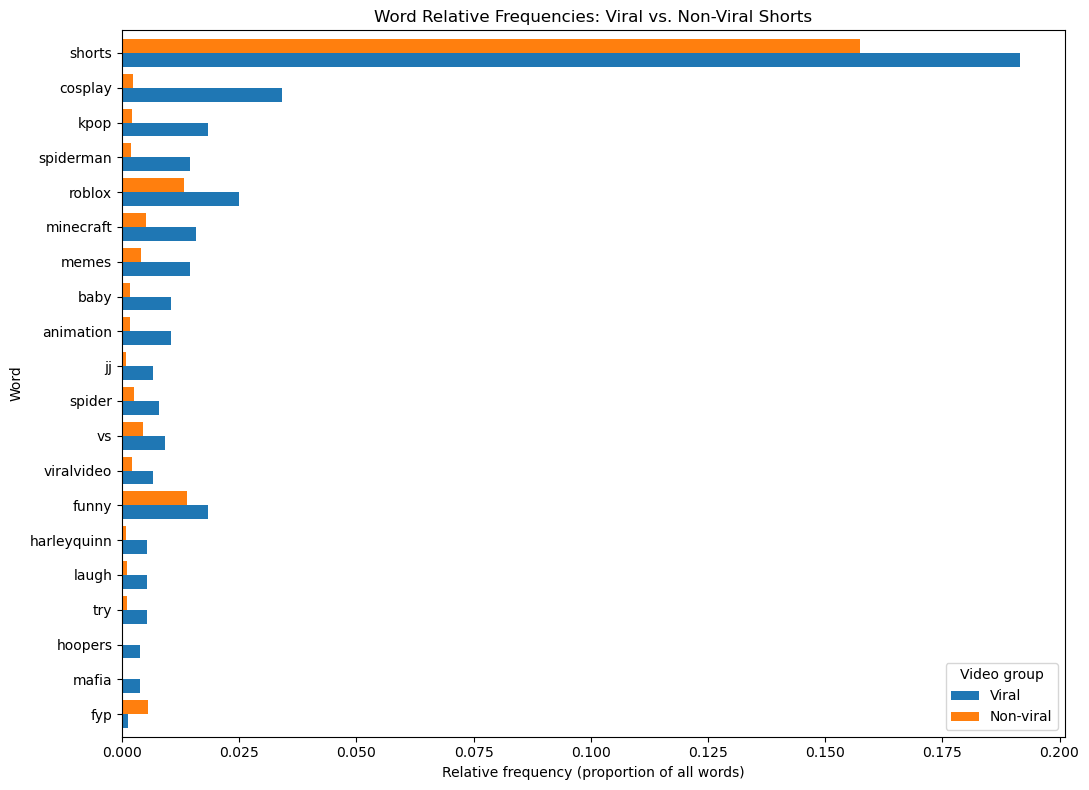

In [56]:
freq_df["Difference"] = freq_df["Viral"] - freq_df["Non-viral"]

top_words = (
    freq_df["Difference"].abs()
    .nlargest(20)
    .index
)

plot_df = freq_df.loc[top_words].sort_values("Difference")

ax = plot_df[["Viral", "Non-viral"]].plot(
    kind="barh",
    figsize=(11, 8),
    width=0.8
)

ax.set_xlabel("Relative frequency (proportion of all words)")
ax.set_ylabel("Word")
ax.set_title("Word Relative Frequencies: Viral vs. Non-Viral Shorts")
ax.legend(title="Video group")

plt.tight_layout()
plt.show()

In [23]:
analysis_df.head()

,title,channel_title,subscriber_count,views_1hr,likes_1hr,views_6hr,likes_6hr,views_24hr,likes_24hr,views_gained_24hr,...,has_question,has_ellipsis,repeated_punctuation,emoji_count,has_emoji,has_hashtag,hashtag_count,has_number,number_count,is_ascii
0,¡Reyyan abofeteó a Yaren!😲| Hercai #shorts,Hercai Español,753000,227.0,9.0,5700.0,364.0,17513.0,763.0,17286.0,...,False,False,False,1,True,True,1,False,0,False
1,#Spider-Man #Gwen #Shorts #Spider-Gwen,正义格温,141000,57327.0,1175.0,324538.0,4667.0,534648.0,7368.0,477321.0,...,False,False,False,0,False,True,4,False,0,True
2,"DeMario ""Pop had 2 tuds"" Douglas 👌 #patriots #...",New England Patriots,420000,4480.0,350.0,15366.0,655.0,21755.0,806.0,17275.0,...,False,False,False,1,True,True,3,True,1,False
3,"Ian Rapoport: ""All Signs Point"" Toward Caleb W...",Bears Now by Chat Sports,174000,4786.0,511.0,42406.0,1450.0,53081.0,1676.0,48295.0,...,False,False,False,0,False,True,3,False,0,True
4,Name: Grey’s Anatomy | She Chose Freedom.🎬🎬 #m...,FurtherEdit,740000,11167.0,932.0,33607.0,1816.0,73092.0,3232.0,61925.0,...,False,False,False,2,True,True,3,False,0,False
